<a href="https://colab.research.google.com/github/angieortegarebollo-max/tareas/blob/main/Cuadratura_adaptable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="text-align: center; color: #d81b60;">
    Cuadratura adaptable mediante la regla de Simpson
</h1>

Se desea aproximar la integral

$$
I=\int_a^b f(x)\,dx
$$

con una tolerancia prescrita \(TOL>0\), sin necesidad de utilizar el mismo tamaño de paso en todo el intervalo.

Para verificar el programa, se empleará el ejemplo de Burden y Faires:

$$
I=\int_1^3 \frac{100}{x^2}
\sin\left(\frac{10}{x}\right)\,dx,
\qquad TOL=10^{-4}.
$$

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import math

Cuadratura adaptable basada en el Algoritmo 4.3 de Burden y Faires, usando la regla de Simpson.

In [17]:
def cuadratura_adaptable(f, a, b, TOL, N):

    if TOL <= 0:
        raise ValEr("TOL debe ser positiva.")
    if a >= b:
        raise ValEr("Se requiere a < b.")
    if N < 1:
        raise ValEr("N debe ser al menos 1.")


    APP = 0.0
    h = (b - a) / 2
    FA = f(a)
    FC = f(a + h)
    FB = f(b)
    S = h * (FA + 4 * FC + FB) / 3
    tole = 10 * TOL
    nivel = 1
    pila = [(a, h, FA, FC, FB, S, tole, nivel)]
    eval = 3
    inter_acep = 0

    while len(pila) > 0:
        ai, hi, FAi, FCi, FBi, Si, TOLi, Li = pila.pop()
        FD = f(ai + hi / 2)
        FE = f(ai + 3 * hi / 2)
        eval += 2
        S1 = hi * (FAi + 4 * FD + FCi) / 6
        S2 = hi * (FCi + 4 * FE + FBi) / 6
        if abs(S1 + S2 - Si) < TOLi:
            APP += S1 + S2
            inter_acep += 1

        else:
            if Li >= N:
                print("NIVEL EXCEDIDO")
                return None

            nueva_TOL = TOLi / 2
            nuevo_nivel = Li + 1
            nuevo_h = hi / 2
            pila.append((
                ai + hi, nuevo_h,
                FCi, FE, FBi, S2,
                nueva_TOL, nuevo_nivel
            ))

            pila.append((
                ai, nuevo_h,
                FAi, FD, FCi, S1,
                nueva_TOL, nuevo_nivel
            ))

    return APP, eval, inter_acep

El ejemplo se ejecutará con los extremos \(a=1\) y \(b=3\), y con la tolerancia \(TOL=10^{-4}\).

In [18]:
def f(x):
    return (100 / x**2) * math.sin(10 / x)
a = 1.0
b = 3.0
TOL = 1e-4
N = 50
resul = cuadratura_adaptable(f, a, b, TOL, N)

if resul is not None:
    APP, eval, inter = resul

    print("=" * 50)
    print("CUADRATURA ADAPTABLE - ALGORITMO 4.3")
    print("=" * 50)
    print(f"Intervalo: [{a}, {b}]")
    print(f"Tolerancia: {TOL:.1e}")
    print(f"Aproximación de la integral: {APP:.9f}")
    print(f"Evaluaciones de la función: {eval}")
    print(f"Intervalos aceptados: {inter}")
    print("=" * 50)

CUADRATURA ADAPTABLE - ALGORITMO 4.3
Intervalo: [1.0, 3.0]
Tolerancia: 1.0e-04
Aproximación de la integral: -1.426014810
Evaluaciones de la función: 93
Intervalos aceptados: 23


La gráfica ayuda a visualizar por qué resulta útil la cuadratura adaptable: la función cambia rápidamente en algunas zonas y presenta oscilaciones a lo largo del intervalo.

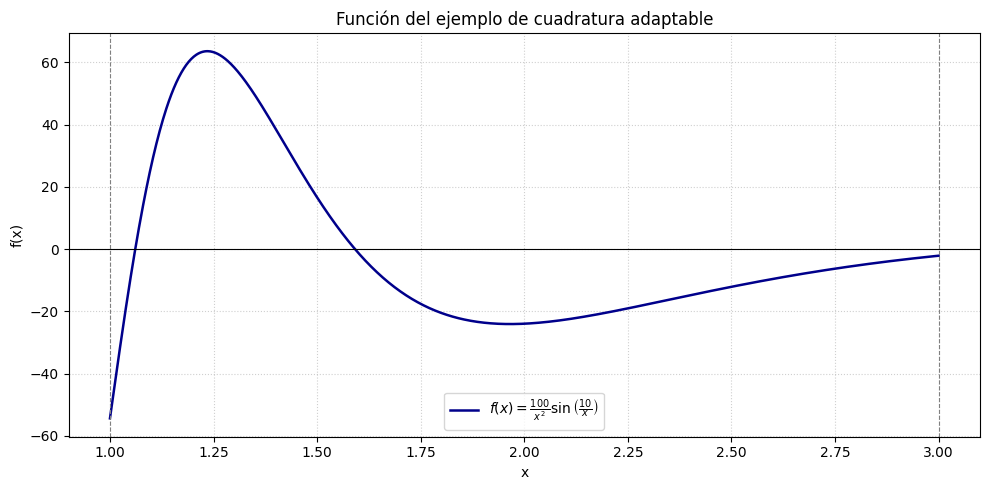

In [20]:
x = np.linspace(1, 3, 1000)
y = (100 / x**2) * np.sin(10 / x)

plt.figure(figsize=(10, 5))

plt.plot(
    x, y,
    color="darkblue",
    linewidth=1.8,
    label=r"$f(x)=\frac{100}{x^2}\sin\left(\frac{10}{x}\right)$"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(3, color="gray", linestyle="--", linewidth=0.8)

plt.title("Función del ejemplo de cuadratura adaptable")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Al aplicar la cuadratura adaptable a la función del ejemplo, se obtiene una aproximación de la integral de aproximadamente \(-1.426014810\).
Para los datos utilizados, el procedimiento acepta 23 subintervalos y realiza 93 evaluaciones de la función. Estos resultados son consistentes con los valores indicados en el ejemplo de Burden y Faires.


In [21]:
valor_refe = 10 * (math.cos(10 / 3) - math.cos(10))

print(f"Valor de referencia: {valor_refe:.9f}")
print(f"Resultado numérico: {APP:.9f}")
print(f"Diferencia absoluta: {abs(APP - valor_refe):.3e}")

Valor de referencia: -1.426024756
Resultado numérico: -1.426014810
Diferencia absoluta: 9.946e-06
